# CatBoost Data Preprocessing and Cleaning
## Employee Resignation Prediction — Model 2 (CatBoost) input preparation

**Student ID:** IT25100565
**Notebook:** `notebooks/team_contributions/preprocessing/IT25100565_Preprocessing.ipynb`
**Input:** `data/raw/Extended_Employee_Performance_and_Productivity_Data.csv`
**Outputs:** `data/processed/catboost/employee_resignation_clean.csv` (git-ignored, like all of `data/processed/` except the split registry), plus `data_dictionary.json`, an anomaly summary and four EDA figures in `results/models/catboost/preprocessing/`

---

### Purpose
This notebook cleans and validates the raw dataset and hands a single, verified file to the Member 2 CatBoost notebook `06_m2_catboost.ipynb`.

### Why every step here is leakage-free
Only **row-wise, stateless** operations are applied: validation checks, whitespace trimming, dropping a column and mapping the target to 0/1.
Nothing is *learned* from the data (no scaler, encoder, imputer, category vocabulary or feature selector is fitted), so running this before the train/test split cannot leak any information from validation or holdout rows.
Every data-dependent step (class weights, CatBoost's categorical statistics, early stopping, tuning, threshold choice) happens later **inside the cross-validation folds** of `06_m2_catboost.ipynb`.

This also respects the group feature contract (`configs/feature_contract.yaml`): the output is a *cleaned* copy of the raw data, not a transformed "universal preprocessed dataset".

| Step | Technique | Applied? |
| :--- | :--- | :--- |
| 1 | Load and fingerprint (SHA-256) | Yes |
| 2 | Schema check and categorical text standardisation | Yes |
| 3 | Missing-value audit | Audit (0 found) |
| 4 | Duplicate audit | Audit (0 found) |
| 5 | Range and validity rules | Yes |
| 6 | IQR outlier analysis | Analysis only (0 found) |
| 7 | Logical-anomaly flags | Flagged, rows kept |
| 8 | Redundancy check (`Hire_Date`, `Monthly_Salary`) | `Hire_Date` dropped |
| 9–11 | EDA and feature–target signal tests | Yes |
| 12–13 | Build and save the processed dataset + data dictionary | Yes |

In [1]:
# ------------------------------------------------------------
# IMPORT LIBRARIES AND SET DISPLAY OPTIONS
# ------------------------------------------------------------
# Import standard-library tools for paths, file fingerprints, JSON and timestamps
from pathlib import Path
import hashlib
import json
from datetime import datetime, timezone

# Import analytical, visualization and statistical-testing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Configure pandas display settings so wide tables are fully visible
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

# Configure visualization settings (inline figures small; saved PNGs use a higher dpi)
plt.rcParams["figure.dpi"] = 90
plt.rcParams["font.size"] = 10
SAVE_DPI = 150

# Define one consistent colour for each class across every figure
COLOR_STAYED = "#4C72B0"
COLOR_RESIGNED = "#DD8452"

# Confirm the library versions used in this run
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.5 | numpy 2.5.3


### Project paths
The notebook walks up from its own folder until it finds the folder that contains `data/raw`. This makes it work from any launch location, including Windows paths with spaces.

In [2]:
# ------------------------------------------------------------
# LOCATE THE PROJECT ROOT AND DEFINE PATHS
# ------------------------------------------------------------
# Walk up from the notebook folder until the folder containing data/raw is found
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data" / "raw").is_dir():
            return candidate
    raise FileNotFoundError("Could not find a folder containing data/raw.")


PROJECT_ROOT = find_project_root()

# Define the input file and the output folders
RAW_FILE = PROJECT_ROOT / "data" / "raw" / "Extended_Employee_Performance_and_Productivity_Data.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "catboost"
FIGURE_DIR = PROJECT_ROOT / "results" / "models" / "catboost" / "preprocessing"

# Define the output files written by this notebook
PROCESSED_FILE = PROCESSED_DIR / "employee_resignation_clean.csv"
DICTIONARY_FILE = FIGURE_DIR / "data_dictionary.json"   # small and committed, so 06_m2_catboost.ipynb can read it in a fresh clone
ANOMALY_FILE = FIGURE_DIR / "logical_anomaly_flags_summary.csv"

# Create the output folders if they do not exist yet
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# Helper: SHA-256 fingerprint with Windows CRLF line endings normalized (same rule as the group loader)
def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes().replace(b"\r\n", b"\n")).hexdigest()


# Helper: show paths relative to the project root so outputs stay machine-independent
def rel(path):
    return Path(path).relative_to(PROJECT_ROOT).as_posix()


# Confirm that the project root and raw file were found
print("Project root found. Raw file:", rel(RAW_FILE))

Project root found. Raw file: data/raw/Extended_Employee_Performance_and_Productivity_Data.csv


## Step 1 — Load and fingerprint the raw dataset
The SHA-256 fingerprint must match the value frozen in the group feature contract. This proves the exact same file is used by every model in the group.

In [3]:
# ------------------------------------------------------------
# STEP 1: LOAD AND VERIFY THE RAW FILE
# ------------------------------------------------------------
# Expected fingerprint and shape, copied from the group feature contract
EXPECTED_RAW_SHA256 = "2b1e07caf58e7678a780d428c1a8893a95d9c4a556134fd8e7368db5ed596cdb"  # from feature_contract.yaml
EXPECTED_SHAPE = (100_000, 20)

# Stop immediately if the raw file is not the exact file used by the group
raw_sha256 = sha256_file(RAW_FILE)
if raw_sha256 != EXPECTED_RAW_SHA256:
    raise ValueError("Raw file fingerprint does not match the group feature contract.")

# Load the raw dataset and confirm it has 100,000 rows and 20 columns
raw_df = pd.read_csv(RAW_FILE)
if raw_df.shape != EXPECTED_SHAPE:
    raise ValueError(f"Unexpected shape {raw_df.shape}; expected {EXPECTED_SHAPE}.")

# Work on a copy so the original raw data is never modified
df = raw_df.copy()   # all cleaning works on a copy; raw_df stays untouched

# Show the verification result and the first rows
print("SHA-256 :", raw_sha256, "-> MATCHES contract")
print("Shape   :", df.shape)
display(df.head(3))

SHA-256 : 2b1e07caf58e7678a780d428c1a8893a95d9c4a556134fd8e7368db5ed596cdb -> MATCHES contract
Shape   : (100000, 20)


,Employee_ID,Department,Gender,Age,Job_Title,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score,Resigned
0,1,IT,Male,55,Specialist,2022-01-19 08:03:05.556036,2,High School,5,6750.0,33,32,22,2,0,14,66,0,2.63,False
1,2,Finance,Male,29,Developer,2024-04-18 08:03:05.556036,0,High School,5,7500.0,34,34,13,14,100,12,61,2,1.72,False
2,3,Finance,Male,55,Specialist,2015-10-26 08:03:05.556036,8,High School,3,5850.0,37,27,6,3,50,10,1,0,3.17,False


## Step 2 — Schema check and categorical text standardisation
Every column must exist with the expected type. The four text columns are trimmed of stray spaces, and each value is checked against the allowed category list from the feature contract. This prevents hidden duplicate categories such as `"IT "` vs `"IT"`, which CatBoost would otherwise treat as two different departments.

In [4]:
# ------------------------------------------------------------
# STEP 2: SCHEMA AND CATEGORY VALIDATION
# ------------------------------------------------------------
# Define the role of each column: identifier, target and date
ID_COLUMN = "Employee_ID"
TARGET = "Resigned"
DATE_COLUMN = "Hire_Date"

# Define the 4 categorical and 13 numeric predictor columns
CATEGORICAL_FEATURES = ["Department", "Gender", "Job_Title", "Education_Level"]
NUMERIC_FEATURES = [
    "Age", "Years_At_Company", "Performance_Score", "Monthly_Salary",
    "Work_Hours_Per_Week", "Projects_Handled", "Overtime_Hours", "Sick_Days",
    "Remote_Work_Frequency", "Team_Size", "Training_Hours", "Promotions",
    "Employee_Satisfaction_Score",
]

# Define the only category labels that are allowed in each categorical column
ALLOWED_CATEGORIES = {   # copied from configs/feature_contract.yaml
    "Department": ["Customer Support", "Engineering", "Finance", "HR", "IT",
                   "Legal", "Marketing", "Operations", "Sales"],
    "Gender": ["Female", "Male", "Other"],
    "Job_Title": ["Analyst", "Consultant", "Developer", "Engineer",
                  "Manager", "Specialist", "Technician"],
    "Education_Level": ["High School", "Bachelor", "Master", "PhD"],
}

# Check that exactly the expected 20 columns are present (none missing, none extra)
expected_columns = [ID_COLUMN, *CATEGORICAL_FEATURES, DATE_COLUMN, *NUMERIC_FEATURES, TARGET]
missing_cols = set(expected_columns) - set(df.columns)
extra_cols = set(df.columns) - set(expected_columns)
if missing_cols or extra_cols:
    raise ValueError(f"Schema mismatch. Missing: {missing_cols}, extra: {extra_cols}")

# Check that every numeric column really has a numeric data type
non_numeric = [c for c in NUMERIC_FEATURES if not pd.api.types.is_numeric_dtype(df[c])]
if non_numeric:
    raise TypeError(f"Numeric columns stored as text: {non_numeric}")

# Trim stray spaces in each text column and reject any unknown category label
category_rows = []
for col in CATEGORICAL_FEATURES:
    before = df[col].astype(str)
    after = before.str.strip()
    changed = int((before != after).sum())
    df[col] = after
    unknown = sorted(set(df[col]) - set(ALLOWED_CATEGORIES[col]))
    if unknown:
        raise ValueError(f"{col} has unexpected categories: {unknown}")
    category_rows.append({"column": col, "levels": df[col].nunique(),
                          "values_trimmed": changed, "unknown_levels": len(unknown)})

# Show the result of the schema and category checks
print("All 20 expected columns present; numeric columns have numeric dtypes.")
display(pd.DataFrame(category_rows))

All 20 expected columns present; numeric columns have numeric dtypes.


,column,levels,values_trimmed,unknown_levels
0,Department,9,0,0
1,Gender,3,0,0
2,Job_Title,7,0,0
3,Education_Level,4,0,0


## Step 3 — Missing-value audit
CatBoost can handle missing numeric values, but an unexpected gap would signal a corrupted file. The rule is: if any value is missing, the notebook stops so the cause can be investigated, rather than silently imputing.

In [5]:
# ------------------------------------------------------------
# STEP 3: MISSING-VALUE AUDIT (WITH FAIL-SAFE)
# ------------------------------------------------------------
# Count missing values in every column and in the whole table
missing = df.isna().sum()
total_missing = int(missing.sum())

# Report overall completeness as a percentage of all cells
print(f"Missing cells: {total_missing:,} of {df.size:,} "
      f"-> completeness {100 * (1 - total_missing / df.size):.2f}%")

# Fail-safe: stop if anything is missing, so it is investigated rather than silently imputed
if total_missing > 0:
    display(missing[missing > 0].to_frame("missing_count"))
    raise ValueError("Missing values found: investigate before imputing anything.")

print("Fail-safe rule passed: no imputation is required.")

Missing cells: 0 of 2,000,000 -> completeness 100.00%
Fail-safe rule passed: no imputation is required.


## Step 4 — Duplicate audit
Duplicate employees would appear in both training and validation folds, which is a hidden form of leakage. Both full-row duplicates and repeated `Employee_ID` values are checked.

In [6]:
# ------------------------------------------------------------
# STEP 4: DUPLICATE AUDIT
# ------------------------------------------------------------
# Count full-row duplicates, duplicates ignoring the ID, and repeated IDs
full_row_duplicates = int(df.duplicated().sum())
feature_duplicates = int(df.drop(columns=[ID_COLUMN]).duplicated().sum())
id_duplicates = int(df[ID_COLUMN].duplicated().sum())

# Report the three duplicate counts
print(f"Full-row duplicates             : {full_row_duplicates}")
print(f"Duplicates ignoring Employee_ID : {feature_duplicates}")
print(f"Duplicate Employee_ID values    : {id_duplicates}")

# Stop if duplicates exist, because they could land in both training and validation folds
if full_row_duplicates or id_duplicates:
    raise ValueError("Duplicates found: they must be resolved before splitting.")
print("No duplicates: every row is a distinct employee.")

Full-row duplicates             : 0
Duplicates ignoring Employee_ID : 0
Duplicate Employee_ID values    : 0
No duplicates: every row is a distinct employee.


## Step 5 — Range and validity rules
Each numeric column is checked against a realistic domain rule (for example, a score must be 1–5 and counts cannot be negative). A failure would mean a corrupted value, which is different from a legitimate extreme value.

In [7]:
# ------------------------------------------------------------
# STEP 5: DOMAIN VALIDITY RULES
# ------------------------------------------------------------
# Define a realistic validity rule for every numeric column
validity_rules = {
    "Age":                         lambda s: s.between(18, 70),
    "Years_At_Company":            lambda s: s.between(0, 50),
    "Performance_Score":           lambda s: s.isin([1, 2, 3, 4, 5]),
    "Monthly_Salary":              lambda s: s > 0,
    "Work_Hours_Per_Week":         lambda s: s.between(1, 80),
    "Projects_Handled":            lambda s: s >= 0,
    "Overtime_Hours":              lambda s: s >= 0,
    "Sick_Days":                   lambda s: s.between(0, 365),
    "Remote_Work_Frequency":       lambda s: s.isin([0, 25, 50, 75, 100]),
    "Team_Size":                   lambda s: s >= 1,
    "Training_Hours":              lambda s: s >= 0,
    "Promotions":                  lambda s: s >= 0,
    "Employee_Satisfaction_Score": lambda s: s.between(1, 5),
}

# Apply each rule and count the rows that break it
validity_rows = []
for col, rule in validity_rules.items():
    invalid = int((~rule(df[col])).sum())
    validity_rows.append({"column": col, "min": df[col].min(), "max": df[col].max(),
                          "unique_values": df[col].nunique(), "invalid_rows": invalid,
                          "status": "PASS" if invalid == 0 else "FAIL"})

# Show the PASS/FAIL table
validity_table = pd.DataFrame(validity_rows)
display(validity_table)

# Stop if any column contains an invalid value
if (validity_table["status"] == "FAIL").any():
    raise ValueError("Invalid values found; see the table above.")

,column,min,max,unique_values,invalid_rows,status
0,Age,22.0,60.0,39,0,PASS
1,Years_At_Company,0.0,10.0,11,0,PASS
2,Performance_Score,1.0,5.0,5,0,PASS
3,Monthly_Salary,3850.0,9000.0,28,0,PASS
4,Work_Hours_Per_Week,30.0,60.0,31,0,PASS
5,Projects_Handled,0.0,49.0,50,0,PASS
6,Overtime_Hours,0.0,29.0,30,0,PASS
7,Sick_Days,0.0,14.0,15,0,PASS
8,Remote_Work_Frequency,0.0,100.0,5,0,PASS
9,Team_Size,1.0,19.0,19,0,PASS


## Step 6 — Outlier analysis (IQR rule)
A value is flagged as an outlier if it lies more than 1.5 × IQR below Q1 or above Q3.
**Decision: no outlier treatment.** No values are flagged. Every column is a bounded, almost uniform range. Tree models split on value order, so they would be unaffected by extreme values anyway.

,column,Q1,Q3,lower_fence,upper_fence,outliers,skewness
0,Age,31.00,51.00,1.00,81.00,0,-0.006
1,Years_At_Company,2.00,7.00,-5.50,14.50,0,0.011
2,Performance_Score,2.00,4.00,-1.00,7.00,0,0.004
3,Monthly_Salary,5250.00,7500.00,1875.00,10875.00,0,0.101
4,Work_Hours_Per_Week,37.00,53.00,13.00,77.00,0,0.010
5,Projects_Handled,12.00,37.00,-25.50,74.50,0,0.010
6,Overtime_Hours,7.00,22.00,-15.50,44.50,0,-0.001
7,Sick_Days,3.00,11.00,-9.00,23.00,0,-0.003
8,Remote_Work_Frequency,25.00,75.00,-50.00,150.00,0,-0.002
9,Team_Size,5.00,15.00,-10.00,30.00,0,-0.001


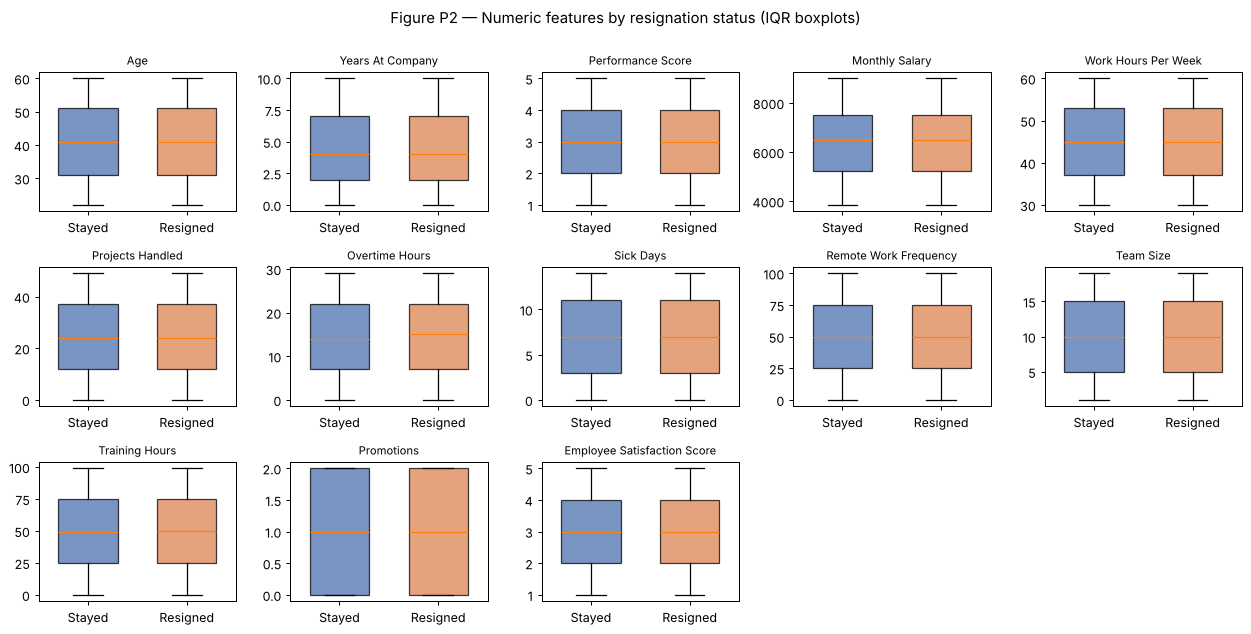

In [8]:
# ------------------------------------------------------------
# STEP 6: IQR OUTLIER ANALYSIS + FIGURE P2
# ------------------------------------------------------------
# Compute the IQR fences (Q1 - 1.5*IQR, Q3 + 1.5*IQR) and count values outside them
outlier_rows = []
for col in NUMERIC_FEATURES:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[col] < low) | (df[col] > high)).sum())
    outlier_rows.append({"column": col, "Q1": q1, "Q3": q3, "lower_fence": low,
                         "upper_fence": high, "outliers": n_out,
                         "skewness": round(df[col].skew(), 3)})

# Show the outlier summary table
outlier_table = pd.DataFrame(outlier_rows)
display(outlier_table)

# Draw one boxplot per numeric feature, comparing stayed vs resigned employees
fig, axes = plt.subplots(3, 5, figsize=(14, 7))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    data = [df.loc[df[TARGET] == False, col], df.loc[df[TARGET] == True, col]]
    box = ax.boxplot(data, patch_artist=True, widths=0.6, showfliers=True)
    # Colour each box by class
    for patch, color in zip(box["boxes"], [COLOR_STAYED, COLOR_RESIGNED]):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
    ax.set_xticks([1, 2], ["Stayed", "Resigned"])
    ax.set_title(col.replace("_", " "), fontsize=9)

# Hide the unused subplot panels
for ax in axes.ravel()[len(NUMERIC_FEATURES):]:
    ax.axis("off")

# Add the title, save the figure and display it
fig.suptitle("Figure P2 — Numeric features by resignation status (IQR boxplots)", y=1.0)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "fig_p2_numeric_boxplots.png", dpi=SAVE_DPI, bbox_inches="tight")
plt.show()

**Interpretation of Figure P2.** For every numeric feature, the boxes for employees who stayed and those who resigned are almost identical, with the same median, spread and range. No points fall outside the whiskers, which confirms 0 IQR outliers. Skewness is between −0.01 and +0.10, so no log or power transform is needed. The plot also gives an early warning: none of these features visibly separates the two classes.

## Step 7 — Logical-anomaly flags
Some combinations are unusual in real life. They are **flagged and reported, not removed**, because:
- the group contract preserves every row unless an exclusion is formally justified;
- removing 4–31% of rows would bias the sample;
- the resignation rate inside each flagged group is still about 10%, so the anomalies are not linked to the target.

In [9]:
# ------------------------------------------------------------
# STEP 7: FLAG LOGICAL ANOMALIES (ROWS ARE KEPT)
# ------------------------------------------------------------
# Define three unusual-but-possible combinations to flag
anomaly_rules = {
    "hire_age_under_18": (df["Age"] - df["Years_At_Company"]) < 18,
    "promotion_with_zero_tenure": (df["Promotions"] > 0) & (df["Years_At_Company"] == 0),
    "overtime_with_under_40h_week": (df["Overtime_Hours"] > 0) & (df["Work_Hours_Per_Week"] < 40),
}

# Count flagged rows and compare the resignation rate inside vs outside each flag
anomaly_rows = []
for name, mask in anomaly_rules.items():
    anomaly_rows.append({"anomaly": name, "rows_flagged": int(mask.sum()),
                         "percent_of_data": round(100 * mask.mean(), 2),
                         "resign_rate_flagged_%": round(100 * df.loc[mask, TARGET].mean(), 2),
                         "resign_rate_not_flagged_%": round(100 * df.loc[~mask, TARGET].mean(), 2)})

# Save and show the anomaly summary (no rows are removed)
anomaly_table = pd.DataFrame(anomaly_rows)
anomaly_table.to_csv(ANOMALY_FILE, index=False)
display(anomaly_table)
print("Rows removed: 0. Summary saved to", rel(ANOMALY_FILE))

,anomaly,rows_flagged,percent_of_data,resign_rate_flagged_%,resign_rate_not_flagged_%
0,hire_age_under_18,3784,3.78,9.65,10.02
1,promotion_with_zero_tenure,6764,6.76,9.49,10.05
2,overtime_with_under_40h_week,31397,31.40,10.08,9.98


Rows removed: 0. Summary saved to results/models/catboost/preprocessing/logical_anomaly_flags_summary.csv


## Step 8 — Redundancy check: `Hire_Date` and `Monthly_Salary`
Two columns may carry no new information:
- `Hire_Date` may simply restate `Years_At_Company`;
- `Monthly_Salary` may be a formula of job title and performance.

In [10]:
# ------------------------------------------------------------
# STEP 8: REDUNDANCY CHECKS
# ------------------------------------------------------------
# Convert Hire_Date to tenure in years, measured from the dataset snapshot date
hire_date = pd.to_datetime(df[DATE_COLUMN])
reference_date = hire_date.max().normalize() + pd.Timedelta(days=4)  # dataset snapshot date
years_from_date = (reference_date - hire_date).dt.days / 365.25

# Check whether Hire_Date simply repeats Years_At_Company, and inspect its time-of-day values
print(f"Correlation(Hire_Date-derived years, Years_At_Company) = "
      f"{np.corrcoef(years_from_date, df['Years_At_Company'])[0, 1]:.4f}")
print("Distinct time-of-day values in Hire_Date:", hire_date.dt.strftime('%H:%M:%S').nunique(),
      "->", hire_date.dt.strftime('%H:%M:%S').iloc[0])

# Count distinct salaries per Job_Title x Performance_Score cell (1 = salary is a fixed formula)
salary_lookup = df.pivot_table(index="Job_Title", columns="Performance_Score",
                               values="Monthly_Salary", aggfunc="nunique")
print("\nDistinct salaries per (Job_Title x Performance_Score) cell "
      "(1 everywhere = salary is fully determined):")
display(salary_lookup)

# Show the actual salary value in each cell
display(df.pivot_table(index="Job_Title", columns="Performance_Score",
                       values="Monthly_Salary", aggfunc="first"))

Correlation(Hire_Date-derived years, Years_At_Company) = 0.9950


Distinct time-of-day values in Hire_Date: 1 -> 08:03:05

Distinct salaries per (Job_Title x Performance_Score) cell (1 everywhere = salary is fully determined):


Performance_Score,1,2,3,4,5
Job_Title,,,,,
Analyst,1,1,1,1,1
Consultant,1,1,1,1,1
Developer,1,1,1,1,1
Engineer,1,1,1,1,1
Manager,1,1,1,1,1
Specialist,1,1,1,1,1
Technician,1,1,1,1,1


Performance_Score,1,2,3,4,5
Job_Title,,,,,
Analyst,4400.0,4800.0,5200.0,5600.0,6000.0
Consultant,6050.0,6600.0,7150.0,7700.0,8250.0
Developer,5500.0,6000.0,6500.0,7000.0,7500.0
Engineer,6600.0,7200.0,7800.0,8400.0,9000.0
Manager,6600.0,7200.0,7800.0,8400.0,9000.0
Specialist,4950.0,5400.0,5850.0,6300.0,6750.0
Technician,3850.0,4200.0,4550.0,4900.0,5250.0


**Decisions.**
- **`Hire_Date` is dropped.** It correlates 0.995 with `Years_At_Company`, and every timestamp has the same time of day, which is an artefact of how the data was generated. Keeping it would add a duplicate signal and let the model learn the generation date.
- **`Monthly_Salary` is kept** in the processed file. Each Job_Title × Performance_Score cell has exactly one salary, so it is fully redundant. The group contract still keeps it in the 17 primary features, so its removal is tested as **variant P2** inside the CatBoost cross-validation rather than decided here.

## Step 9 — EDA: target distribution

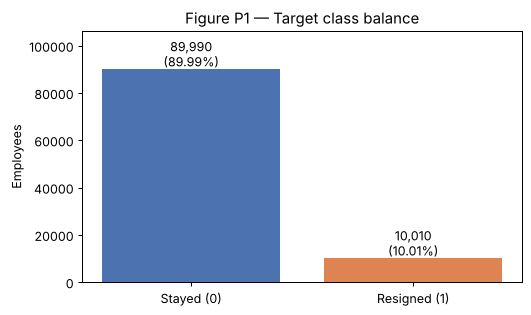

Imbalance ratio = 8.99 : 1


In [11]:
# ------------------------------------------------------------
# STEP 9: TARGET DISTRIBUTION + FIGURE P1
# ------------------------------------------------------------
# Count employees in each class and convert to percentages
target_counts = df[TARGET].value_counts().reindex([False, True])
target_pct = 100 * target_counts / len(df)

# Draw a bar chart of the two classes
fig, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.bar(["Stayed (0)", "Resigned (1)"], target_counts.values,
              color=[COLOR_STAYED, COLOR_RESIGNED])

# Write the count and percentage on top of each bar
for bar, n, p in zip(bars, target_counts.values, target_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n:,}\n({p:.2f}%)",
            ha="center", va="bottom")

# Label the axes, save the figure and display it
ax.set_ylabel("Employees")
ax.set_ylim(0, target_counts.max() * 1.18)
ax.set_title("Figure P1 — Target class balance")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "fig_p1_target_distribution.png", dpi=SAVE_DPI, bbox_inches="tight")
plt.show()

# Report the class imbalance ratio
print(f"Imbalance ratio = {target_counts[False] / target_counts[True]:.2f} : 1")

**Interpretation of Figure P1.** Only 10.01% of employees resigned (a 9 : 1 imbalance). This has three consequences for the CatBoost notebook:
1. A model that always predicts "stayed" already reaches about 90% accuracy, so accuracy is misleading. **PR-AUC** is the primary metric.
2. Folds are **stratified**, so every fold keeps about 10% resigners.
3. Imbalance is handled with CatBoost's `auto_class_weights` inside each training fold, not with SMOTE. SMOTE applied before splitting would copy information into the validation rows.

## Step 10 — EDA: resignation rate by category (chi-square test)

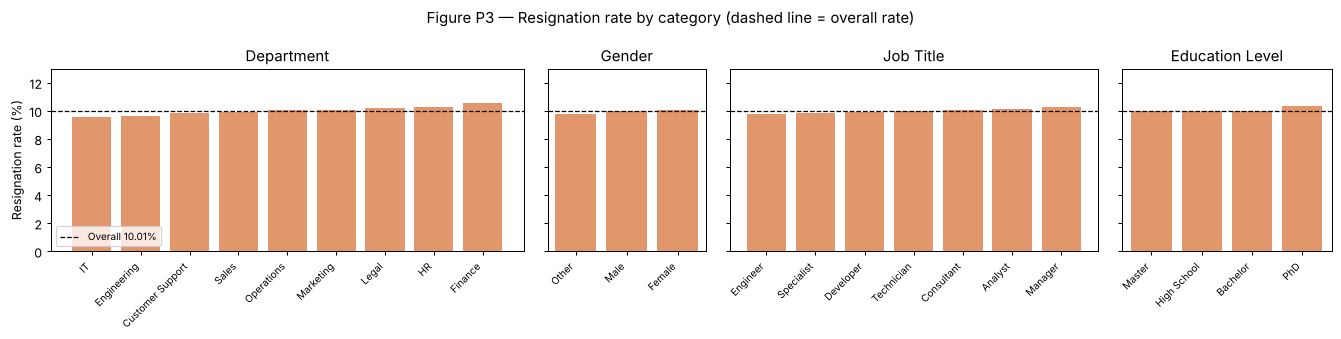

,feature,chi2,dof,p_value,min_rate_%,max_rate_%
0,Department,9.18,8,0.3274,9.56,10.54
1,Gender,0.32,2,0.8523,9.75,10.03
2,Job_Title,2.72,6,0.8435,9.80,10.26
3,Education_Level,0.55,3,0.9068,9.98,10.31


In [12]:
# ------------------------------------------------------------
# STEP 10: CATEGORY vs TARGET + FIGURE P3
# ------------------------------------------------------------
# Overall resignation rate, used as the reference line in every panel
overall_rate = 100 * df[TARGET].mean()
chi_rows = []

# Create one panel per categorical feature (panel width follows the number of levels)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True,
                         gridspec_kw={"width_ratios": [9, 3, 7, 4]})
for ax, col in zip(axes, CATEGORICAL_FEATURES):
    # Plot the resignation rate of each category against the overall rate
    rate = 100 * df.groupby(col)[TARGET].mean().sort_values()
    ax.bar(rate.index, rate.values, color=COLOR_RESIGNED, alpha=0.85)
    ax.axhline(overall_rate, color="black", linestyle="--", linewidth=1,
               label=f"Overall {overall_rate:.2f}%")
    ax.set_title(col.replace("_", " "))
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")
    # Chi-square test: is this category associated with resignation?
    chi2, p_value, dof, _ = stats.chi2_contingency(pd.crosstab(df[col], df[TARGET]))
    chi_rows.append({"feature": col, "chi2": round(chi2, 2), "dof": dof,
                     "p_value": round(p_value, 4),
                     "min_rate_%": round(rate.min(), 2), "max_rate_%": round(rate.max(), 2)})

# Label the shared axis, save the figure and display it
axes[0].set_ylabel("Resignation rate (%)")
axes[0].set_ylim(0, 13)
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Figure P3 — Resignation rate by category (dashed line = overall rate)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "fig_p3_resignation_rate_by_category.png", dpi=SAVE_DPI, bbox_inches="tight")
plt.show()

# Show the chi-square test results
display(pd.DataFrame(chi_rows))

**Interpretation of Figure P3.** In every department, gender, job title and education level, the resignation rate stays within about 9.5–10.5%, very close to the overall 10.01%. All chi-square p-values are well above 0.05, so no category is significantly associated with resignation. These are still passed to CatBoost as native `cat_features`, because a model can sometimes find interactions that one-variable tests miss.

## Step 11 — EDA: numeric features vs target and correlation matrix
Two complementary tests are used for each numeric feature:
- **Mann–Whitney U**: are the distributions different for stayers and resigners? It needs no normality assumption.
- **Point-biserial r**: the linear correlation with the 0/1 target.

,feature,mean_stayed,mean_resigned,mann_whitney_p,point_biserial_r
8,Remote_Work_Frequency,50.006,50.854,0.0227,0.0072
0,Age,41.016,41.148,0.2664,0.0035
12,Employee_Satisfaction_Score,3.000,2.989,0.3740,-0.0028
2,Performance_Score,2.997,2.984,0.3912,-0.0027
6,Overtime_Hours,14.508,14.577,0.4515,0.0024
7,Sick_Days,7.006,7.031,0.5851,0.0017
5,Projects_Handled,24.439,24.357,0.5893,-0.0017
3,Monthly_Salary,6403.909,6396.938,0.6166,-0.0015
10,Training_Hours,49.495,49.608,0.7131,0.0012
9,Team_Size,10.015,9.998,0.7665,-0.0009


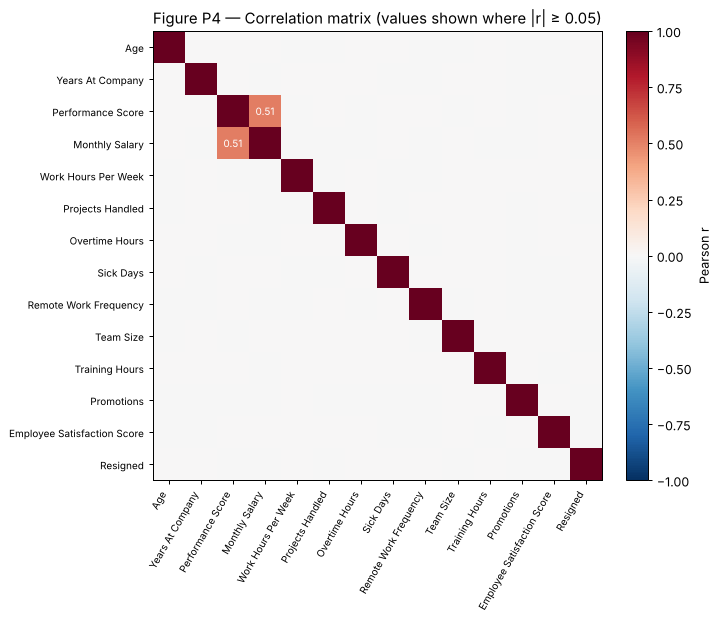

In [13]:
# ------------------------------------------------------------
# STEP 11: NUMERIC SIGNAL TESTS + FIGURE P4
# ------------------------------------------------------------
# Convert the target to 0/1 for the statistical tests
y01 = df[TARGET].astype(int)

# For each numeric feature: compare class means, Mann-Whitney U test and point-biserial correlation
signal_rows = []
for col in NUMERIC_FEATURES:
    stayed, resigned = df.loc[y01 == 0, col], df.loc[y01 == 1, col]
    signal_rows.append({"feature": col,
                        "mean_stayed": round(stayed.mean(), 3),
                        "mean_resigned": round(resigned.mean(), 3),
                        "mann_whitney_p": round(stats.mannwhitneyu(stayed, resigned).pvalue, 4),
                        "point_biserial_r": round(stats.pointbiserialr(y01, df[col])[0], 4)})

# Show the test results, most significant first
signal_table = pd.DataFrame(signal_rows).sort_values("mann_whitney_p")
display(signal_table)

# Compute the correlation matrix of the numeric features plus the target
corr = df[NUMERIC_FEATURES].assign(Resigned=y01).corr()

# Draw the correlation matrix as a heatmap
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
labels = [c.replace("_", " ") for c in corr.columns]
ax.set_xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(labels)), labels, fontsize=8)

# Print the value inside each cell where |r| >= 0.05 (skipping the diagonal)
for i in range(len(labels)):
    for j in range(len(labels)):
        value = corr.values[i, j]
        if i != j and abs(value) >= 0.05:
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8, color="white")

# Add the colour bar and title, save the figure and display it
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson r")
ax.set_title("Figure P4 — Correlation matrix (values shown where |r| ≥ 0.05)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "fig_p4_correlation_matrix.png", dpi=SAVE_DPI, bbox_inches="tight")
plt.show()

**Interpretation of the signal tests and Figure P4.**
- The largest correlation with `Resigned` is under 0.01 in absolute value. Only `Remote_Work_Frequency` has a Mann-Whitney p below 0.05 (about 0.02), and with 13 tests that is what chance alone would produce about half the time.
- The only strong correlation between features is `Performance_Score` with `Monthly_Salary` (r ≈ 0.51), caused by the salary formula found in Step 8. Every other pair is close to 0, so there is no multicollinearity problem.

**Key finding for the modelling stage:** the individual features have essentially no linear, rank-based or categorical relationship with resignation. `06_m2_catboost.ipynb` tests whether a non-linear model can find interactions the simple tests miss. It compares the model against no-skill Dummy baselines to judge the result honestly.

## Step 12 — Build the processed dataset
Only three changes are made to the data:
1. `Hire_Date` is dropped (Step 8).
2. `Resigned` is mapped from True/False to **1/0** (1 = resigned, the positive class).
3. Columns are ordered as `Employee_ID`, the 4 categorical features, the 13 numeric features, then `Resigned`.

`Employee_ID` is kept as a **key column only**: it is needed to join the group's split registry and to trace predictions. It is never used as a feature.

In [14]:
# ------------------------------------------------------------
# STEP 12: BUILD THE PROCESSED DATASET
# ------------------------------------------------------------
# The 17 predictors in a fixed order: 4 categorical followed by 13 numeric
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

# Drop Hire_Date, map the target True/False to 1/0, and order the columns
processed_df = df.drop(columns=[DATE_COLUMN]).copy()
processed_df[TARGET] = processed_df[TARGET].map({False: 0, True: 1}).astype(int)
processed_df = processed_df[[ID_COLUMN, *FEATURES, TARGET]]

# Final integrity checks
assert processed_df.shape == (100_000, 19)
assert processed_df[TARGET].isin([0, 1]).all()
assert DATE_COLUMN not in processed_df.columns
assert processed_df.isna().sum().sum() == 0
assert int(processed_df[TARGET].sum()) == int(raw_df[TARGET].sum())

# Show the shape, the positive-class count and the first rows
print("Processed shape:", processed_df.shape)
print("Positive class (Resigned=1):", int(processed_df[TARGET].sum()),
      f"({100 * processed_df[TARGET].mean():.2f}%)")
display(processed_df.head(3))

Processed shape: (100000, 19)
Positive class (Resigned=1): 10010 (10.01%)


,Employee_ID,Department,Gender,Job_Title,Education_Level,Age,Years_At_Company,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score,Resigned
0,1,IT,Male,Specialist,High School,55,2,5,6750.0,33,32,22,2,0,14,66,0,2.63,0
1,2,Finance,Male,Developer,High School,29,0,5,7500.0,34,34,13,14,100,12,61,2,1.72,0
2,3,Finance,Male,Specialist,High School,55,8,3,5850.0,37,27,6,3,50,10,1,0,3.17,0


## Step 13 — Save the processed dataset and the data dictionary
`data_dictionary.json` records each column's role, its allowed categories or observed numeric range, and both file fingerprints. `06_m2_catboost.ipynb` uses it to verify its input. The manual-input form uses it to fill the dropdowns.

In [15]:
# ------------------------------------------------------------
# STEP 13: SAVE OUTPUTS
# ------------------------------------------------------------
# Save the processed dataset and fingerprint it so CatBoost.ipynb can verify it
processed_df.to_csv(PROCESSED_FILE, index=False, lineterminator="\n")
processed_sha256 = sha256_file(PROCESSED_FILE)

# Build the data dictionary: column roles, allowed categories, numeric ranges and fingerprints
data_dictionary = {
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "created_by": "IT25100565_Preprocessing.ipynb",
    "raw_file": rel(RAW_FILE),
    "raw_sha256": raw_sha256,
    "processed_file": rel(PROCESSED_FILE),
    "processed_sha256": processed_sha256,
    "rows": int(len(processed_df)),
    "id_column": ID_COLUMN,
    "target": {"column": TARGET, "positive_class": 1, "mapping": {"False": 0, "True": 1},
               "positive_rate": round(float(processed_df[TARGET].mean()), 6)},
    "dropped_columns": {DATE_COLUMN: "Redundant with Years_At_Company (r = 0.995); generation artefact."},
    "categorical_features": {c: ALLOWED_CATEGORIES[c] for c in CATEGORICAL_FEATURES},
    "numeric_features": {
        c: {"dtype": str(processed_df[c].dtype),
            "min": float(processed_df[c].min()), "max": float(processed_df[c].max()),
            **({"allowed_values": sorted(int(v) for v in processed_df[c].unique())}
               if processed_df[c].nunique() <= 5 else {})}
        for c in NUMERIC_FEATURES},
    "feature_order": FEATURES,
    "row_removals": 0,
    "transformations_learned_from_data": "none",
}

# Write the data dictionary to JSON
with open(DICTIONARY_FILE, "w", encoding="utf-8") as f:
    json.dump(data_dictionary, f, indent=2)

# Confirm what was saved
print("Saved:", rel(PROCESSED_FILE), f"({PROCESSED_FILE.stat().st_size / 1e6:.1f} MB)")
print("Saved:", rel(DICTIONARY_FILE))
print("Processed SHA-256:", processed_sha256)
print("Figures:", sorted(p.name for p in FIGURE_DIR.glob("*.png")))

Saved: data/processed/catboost/employee_resignation_clean.csv (8.2 MB)
Saved: results/models/catboost/preprocessing/data_dictionary.json
Processed SHA-256: 9e0bd42658bf0faeffc276e9307522b04699cf51e04cfeaaa67b63e2e4f5b2c1
Figures: ['fig_p1_target_distribution.png', 'fig_p2_numeric_boxplots.png', 'fig_p3_resignation_rate_by_category.png', 'fig_p4_correlation_matrix.png']


## Summary

| Check | Result | Action |
| :--- | :--- | :--- |
| Fingerprint | Matches group contract | — |
| Missing values | 0 | No imputation |
| Duplicates | 0 rows, 0 IDs | None |
| Validity rules | All 13 columns pass | None |
| IQR outliers | 0 | None; trees are robust to outliers anyway |
| Logical anomalies | Flagged; target rate unchanged | Rows kept |
| `Hire_Date` | Duplicates `Years_At_Company` | **Dropped** |
| `Monthly_Salary` | Fully determined by title × performance | Kept; removal tested as variant P2 |
| Target | 10.01% resigned (9 : 1) | Mapped to 1/0; PR-AUC + stratified folds downstream |
| Feature–target signal | No test significant beyond chance | Judged against Dummy baselines downstream |

**Deliberately not applied:**
- **Scaling:** trees are scale-invariant.
- **One-hot or label encoding:** CatBoost handles categories natively with ordered target statistics.
- **SMOTE:** it leaks information when applied before the split and distorts probabilities.
- **PCA:** there is no correlated structure to compress, and it would remove interpretability.
- **Target-based feature selection on the full data:** that is leakage.

**Next:** `notebooks/team_contributions/models/member_2_catboost/06_m2_catboost.ipynb` loads `data/processed/catboost/employee_resignation_clean.csv` and `results/models/catboost/preprocessing/data_dictionary.json`.